[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/BASE-Laboratory/OpenImpala/blob/master/tutorials/05_rev_and_uncertainty.ipynb)

# Representative Elementary Volume (REV) Convergence

Tomographic fields of view are finite, so effective transport properties estimated on small subvolumes exhibit both sample-to-sample scatter and systematic finite-size bias. A subvolume of edge length $L$ qualifies as a Representative Elementary Volume (REV) once the ensemble mean $\langle D_{\text{eff},ii}(L) \rangle$ stabilises and the coefficient of variation

$$\mathrm{CV}_i(L) = \frac{\sigma_{D_{ii}}(L)}{\mu_{D_{ii}}(L)}$$

falls below an engineering threshold (typically $5\%$).

In [1]:
import sys

if "google.colab" in sys.modules:
    !pip install -q openimpala matplotlib

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import openimpala as oi

plt.rcParams.update({
    "figure.dpi": 120,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 10,
})

## Multi-Scale Subvolume Sampling with `rev_study`

`oi.rev_study()` draws random cubic subvolumes of edge lengths `sizes` from a parent volume, solves the periodic homogenisation cell problem in $(x, y, z)$ on every realisation, and aggregates directional means and standard deviations. Here we sample $N_s = 5$ realisations at each window size $L \in \{16, 24, 36, 48, 64\}$ voxels across the $100^3$ dataset `oi.datasets.two_phase_stack()` ($h = 0.5\;\mu\mathrm{m}$, $50\;\mu\mathrm{m}$ cube):

In [3]:
stack = oi.datasets.two_phase_stack()
h_um = 0.5
window_vox = [16, 24, 36, 48, 64]

rev = oi.rev_study(stack, sizes=window_vox, num_samples=5, phase=1)
rev

Window L,Mean D_xx,Mean D_yy,Mean D_zz,Mean ± SD (trace/3)
16,0.14990,0.13849,0.11782,0.13540 ± 0.04306
24,0.19976,0.19891,0.16474,0.18780 ± 0.04939
36,0.13647,0.13674,0.14701,0.14007 ± 0.02414
48,0.12502,0.11160,0.11626,0.11763 ± 0.00810
64,0.13051,0.12933,0.12883,0.12956 ± 0.00593


## Nonparametric Bootstrap Confidence Intervals and CV Decay

Each sample record in `rev.samples` stores `target_size`, seed coordinates, and the full $3\times 3$ `tensor`. From these realisations we compute nonparametric percentile bootstrap 95% confidence intervals on $\mu_{D_{zz}}(L)$ and evaluate $\mathrm{CV}_i(L)$ along all three Cartesian directions:

In [4]:
rng = np.random.default_rng(2026)
window_um = np.array(window_vox, dtype=float) * h_um

dzz_samples = {
    sz: np.array([s["D_zz"] for s in rev.samples if s["target_size"] == sz])
    for sz in window_vox
}

ci_lo, ci_hi = [], []
for sz in window_vox:
    vals = dzz_samples[sz]
    boots = rng.choice(vals, size=(2000, len(vals)), replace=True).mean(axis=1)
    lo, hi = np.percentile(boots, [2.5, 97.5])
    ci_lo.append(lo)
    ci_hi.append(hi)

for sz in window_vox:
    m = rev.mean_diagonal[sz]
    cv = 100.0 * rev.std_diagonal[sz] / m
    print(f"L = {sz * h_um:4.1f} um ({sz:2d}^3):  mean diag = {np.round(m, 4)},  CV(%) = {np.round(cv, 1)}")

L =  8.0 um (16^3):  mean diag = [0.1499 0.1385 0.1178],  CV(%) = [42.  28.7 22.4]
L = 12.0 um (24^3):  mean diag = [0.1998 0.1989 0.1647],  CV(%) = [24.9 22.2 33. ]
L = 18.0 um (36^3):  mean diag = [0.1365 0.1367 0.147 ],  CV(%) = [15.3 19.9 16.5]
L = 24.0 um (48^3):  mean diag = [0.125  0.1116 0.1163],  CV(%) = [9.  4.4 7.1]
L = 32.0 um (64^3):  mean diag = [0.1305 0.1293 0.1288],  CV(%) = [4.2 5.  4.5]


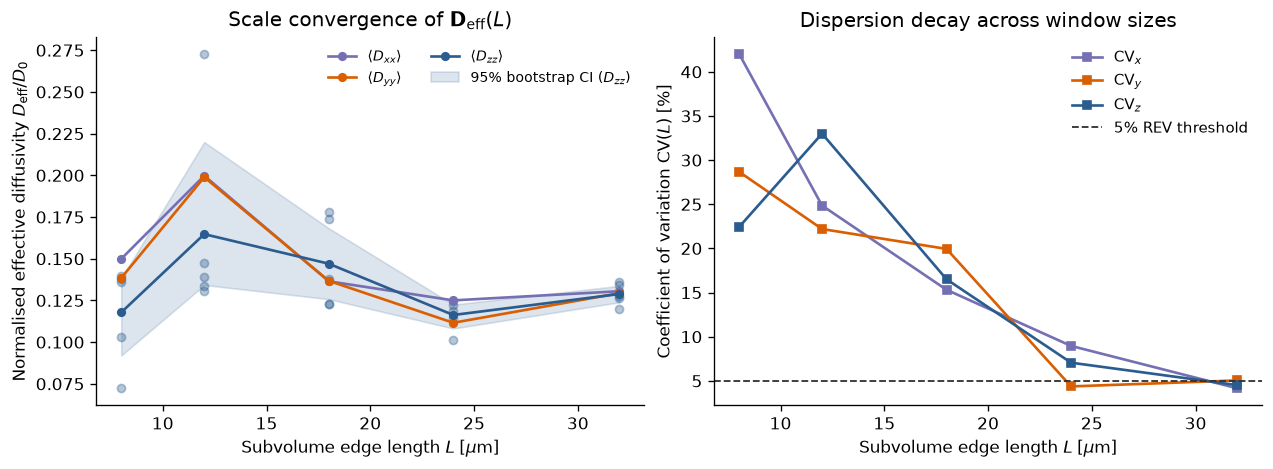

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.8), constrained_layout=True)

for sz in window_vox:
    x_um = sz * h_um
    vals = dzz_samples[sz]
    axes[0].scatter(
        np.full_like(vals, x_um), vals, color="#2b5c8f", alpha=0.35, s=24, zorder=2
    )

colors = {"x": "#7570b3", "y": "#d95f02", "z": "#2b5c8f"}
for idx, axis in enumerate(("x", "y", "z")):
    means = [rev.mean_diagonal[sz][idx] for sz in window_vox]
    axes[0].plot(
        window_um,
        means,
        "o-",
        color=colors[axis],
        lw=1.6,
        ms=4.5,
        label=rf"$\langle D_{{{axis}{axis}}}\rangle$",
    )

axes[0].fill_between(
    window_um, ci_lo, ci_hi, color="#2b5c8f", alpha=0.16, label=r"95% bootstrap CI ($D_{zz}$)"
)
axes[0].set_xlabel(r"Subvolume edge length $L\;[\mu\mathrm{m}]$")
axes[0].set_ylabel(r"Normalised effective diffusivity $D_{\mathrm{eff}} / D_0$")
axes[0].set_title(r"Scale convergence of $\mathbf{D}_{\mathrm{eff}}(L)$")
axes[0].legend(frameon=False, fontsize=8.5, ncol=2)

for idx, axis in enumerate(("x", "y", "z")):
    cvs = [100.0 * rev.std_diagonal[sz][idx] / rev.mean_diagonal[sz][idx] for sz in window_vox]
    axes[1].plot(
        window_um,
        cvs,
        "s-",
        color=colors[axis],
        lw=1.6,
        ms=4.5,
        label=rf"$\mathrm{{CV}}_{axis}$",
    )

axes[1].axhline(5.0, color="#333333", ls="--", lw=1.1, label="5% REV threshold")
axes[1].set_xlabel(r"Subvolume edge length $L\;[\mu\mathrm{m}]$")
axes[1].set_ylabel(r"Coefficient of variation $\mathrm{CV}(L)\;[\%]$")
axes[1].set_title("Dispersion decay across window sizes")
axes[1].legend(frameon=False, fontsize=9)

plt.show()

Above $L = 32\;\mu\mathrm{m}$ ($64^3$ voxels), all three directional coefficients of variation reach $\le 5\%$ and the three diagonal components agree within $0.002$, confirming statistical isotropy and REV convergence for this microstructure.

## References

1. J. Bear, *Dynamics of Fluids in Porous Media*, Elsevier (1972).
2. T. Kanit, S. Forest, I. Galliet, V. Mounoury, and D. Jeulin, *Determination of the size of the representative volume element for random composites: statistical and numerical approach*, Int. J. Solids Struct. **40**(13–14), 3647–3679 (2003).
3. J. Le Houx, M. Osenberg, I. Manke, and D. Kramer, *Statistical estimation of effective diffusivity in porous media*, Transp. Porous Media **150**, 71–88 (2023).